# 7.5 — Class Imbalance: Metrics, Resampling and Better Decisions

**Learning goals**
- Identify why accuracy can be misleading and **choose the positive class deliberately**.
- Explain confusion-matrix metrics, ROC and Precision–Recall (PR) curves.
- Compare class weights, random over/undersampling and SMOTE critically.
- Prevent data leakage with stratified CV and `imblearn.pipeline.Pipeline`.
- Explore thresholds without retraining; recognize that algorithms respond differently to imbalance.

> **Key message:** The goal is **not** to obtain a perfectly balanced dataset. It is to improve decisions for the problem we want to solve.

**Prerequisites:** logistic regression, preprocessing pipelines, classification metrics and cross-validation. Advanced threshold selection (Youden's J), cost-based decisions, calibration, XGBoost and LightGBM belong to the optional self-learning notebook.

## 0. Setup, source and license

Install in the **same Conda environment** as your Jupyter kernel, then restart the kernel if needed:

```bash
conda activate YOUR_ENVIRONMENT
conda install -c conda-forge imbalanced-learn
```

**Dataset:** [Online Shoppers Purchasing Intention Dataset — UCI](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), 12,330 shopping sessions. The target `Revenue` indicates whether a session ended in a purchase.

**License:** CC BY 4.0 permits commercial reuse with appropriate attribution. Dataset attribution: Sakar, C. O. et al. (2018), *Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks*, Neural Computing and Applications; [UCI dataset record](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). Data are downloaded at runtime, not redistributed with this notebook.

In [ ]:
import io
import zipfile
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

RANDOM_STATE = 42
POSITIVE_CLASS = True  # A purchase: the business event we want to detect.
DATA_URL = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"

with urlopen(DATA_URL, timeout=40) as response:
    archive_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    csv_names = [name for name in archive.namelist() if name.lower().endswith(".csv")]
    if len(csv_names) != 1:
        raise ValueError(f"Expected one CSV; found: {csv_names}")
    with archive.open(csv_names[0]) as csv_file:
        data = pd.read_csv(csv_file)

print("Dataset shape:", data.shape)
print(data["Revenue"].value_counts(dropna=False))
data.head()

## 1. Which class is positive?

Here **positive = purchase (`Revenue=True`)**. The positive class is a choice driven by the question, **not necessarily the minority class**.

- **Precision:** Of sessions predicted as purchases, what fraction actually purchased?
- **Recall:** Of sessions that actually purchased, what fraction did we detect?

For a poisonous-mushroom classifier, we might define *poisonous* as positive. Predicting *safe* for a poisonous mushroom would then be a **false negative**, potentially a very costly error.

**Check for understanding (2 min):** If the business instead wants to detect sessions that will *not* purchase, which class is positive? Does the dataset change?

In [ ]:
counts = data["Revenue"].value_counts().reindex([False, True])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(["No purchase", "Purchase"], counts.to_numpy())
ax.set(ylabel="Number of sessions", title="Original class distribution")
for i, count in enumerate(counts):
    ax.text(i, count, f"{count:,} ({count / len(data):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 2. Split first, define features explicitly

Keep the **test set untouched** until the final evaluation. `stratify=y` preserves approximately the original class proportions in both partitions.

**Important:** A feature may be categorical even when stored as an integer. Do not rely exclusively on pandas `dtype` (`object` vs `str` also differs across pandas versions). We explicitly specify feature semantics.

`OneHotEncoder(handle_unknown="ignore")` encodes an unseen category at prediction time as **all zeros for that feature's encoded columns**. It does **not** remove the row, and the model has not learned a meaning for the unseen category.

We use `MinMaxScaler` so numeric features have a range comparable to 0/1 dummy columns **on training data**. This does not make all features equally important for distances. Validation/test values can lie outside [0, 1] if they exceed the training range. The scaler must be fitted within each training fold.

In [ ]:
X = data.drop(columns="Revenue")
y = data["Revenue"]  # Keep the original boolean labels.

# Feature meaning, not storage dtype, determines the preprocessing.
categorical_cols = [
    "Month", "OperatingSystems", "Browser", "Region", "TrafficType",
    "VisitorType", "Weekend",
]
numeric_cols = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
assert set(categorical_cols + numeric_cols) == set(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ("numeric", MinMaxScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

print("Train purchase prevalence:", f"{y_train.mean():.1%}")
print("Test purchase prevalence: ", f"{y_test.mean():.1%}")
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

## 3. A misleadingly good baseline: `DummyClassifier`

A classifier that always predicts *no purchase* can achieve high accuracy while failing to detect any purchases.

**Our confusion-matrix convention throughout:** **rows = predicted**, **columns = actual**. Scikit-learn's `confusion_matrix` uses the opposite convention, so we transpose it before plotting.

**Recall the four cells (positive = purchase):**

- **TP (true positive):** predicted purchase, actual purchase.
- **FP (false positive):** predicted purchase, actual no purchase.
- **FN (false negative):** predicted no purchase, actual purchase.
- **TN (true negative):** predicted no purchase, actual no purchase.

With a model that never predicts positive, `TP = FP = 0`. Mathematically, **precision = 0/0 is undefined**; recall is **0** (provided actual positives exist). Scikit-learn's `zero_division=0` **conventionally reports precision as 0**. Do not confuse this convention with the mathematical definition.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_train)  # Training illustration; test remains untouched.

print(classification_report(y_train, dummy_pred, labels=[False, True], zero_division=0))
cm = confusion_matrix(y_train, dummy_pred, labels=[False, True]).T
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["No purchase", "Purchase"],
       yticklabels=["No purchase", "Purchase"],
       xlabel="Actual", ylabel="Predicted", title="Dummy classifier")
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

**Check for understanding (2 min):** For the positive class (purchase), which metric is mathematically undefined, which is zero, and why is accuracy still high?

## 4. Classification metrics — quick reference

Let **TP** = predicted purchase and actual purchase; **FP** = predicted purchase but no purchase; **FN** = predicted no purchase but actual purchase; **TN** = predicted no purchase and actual no purchase.

| Metric | Formula | Question |
|---|---|---|
| Accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ | What fraction of all decisions is correct? |
| Precision | $\frac{TP}{TP+FP}$ | How reliable are predicted purchases? |
| Recall = Sensitivity = TPR | $\frac{TP}{TP+FN}$ | What fraction of actual purchases is detected? |
| Specificity = TNR | $\frac{TN}{TN+FP}$ | What fraction of non-purchases is correctly rejected? |
| FPR | $\frac{FP}{FP+TN}=1-\mathrm{TNR}$ | What fraction of non-purchases is falsely flagged? |
| F1 | $2\frac{\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}$ | Harmonic mean of precision and recall |

These threshold-dependent metrics assume a defined positive class; denominators can be zero. **ROC-AUC** and **Average Precision (AP)** summarize performance over multiple score thresholds.

**AP is a summary of the PR curve**, computed as

$$AP=\sum_n(R_n-R_{n-1})P_n$$

where $P_n$ and $R_n$ are precision and recall at successive points **ordered by increasing recall**. This stepwise sum is **not generally equal** to the area calculated by trapezoidal interpolation (*trapezoidal PR-AUC*). In scikit-learn, use `average_precision_score` or `scoring="average_precision"`. For a no-skill ranking, AP is approximately the positive prevalence.

### Visual guide: which confusion-matrix cells enter each metric?

All diagrams use **rows = predicted**, **columns = actual**, with the positive class first: `[[TP, FP], [FN, TN]]`. **Green = numerator; blue = denominator only; gray = unused.** For F1, the highlighted cells correspond to the equivalent count-based formula.

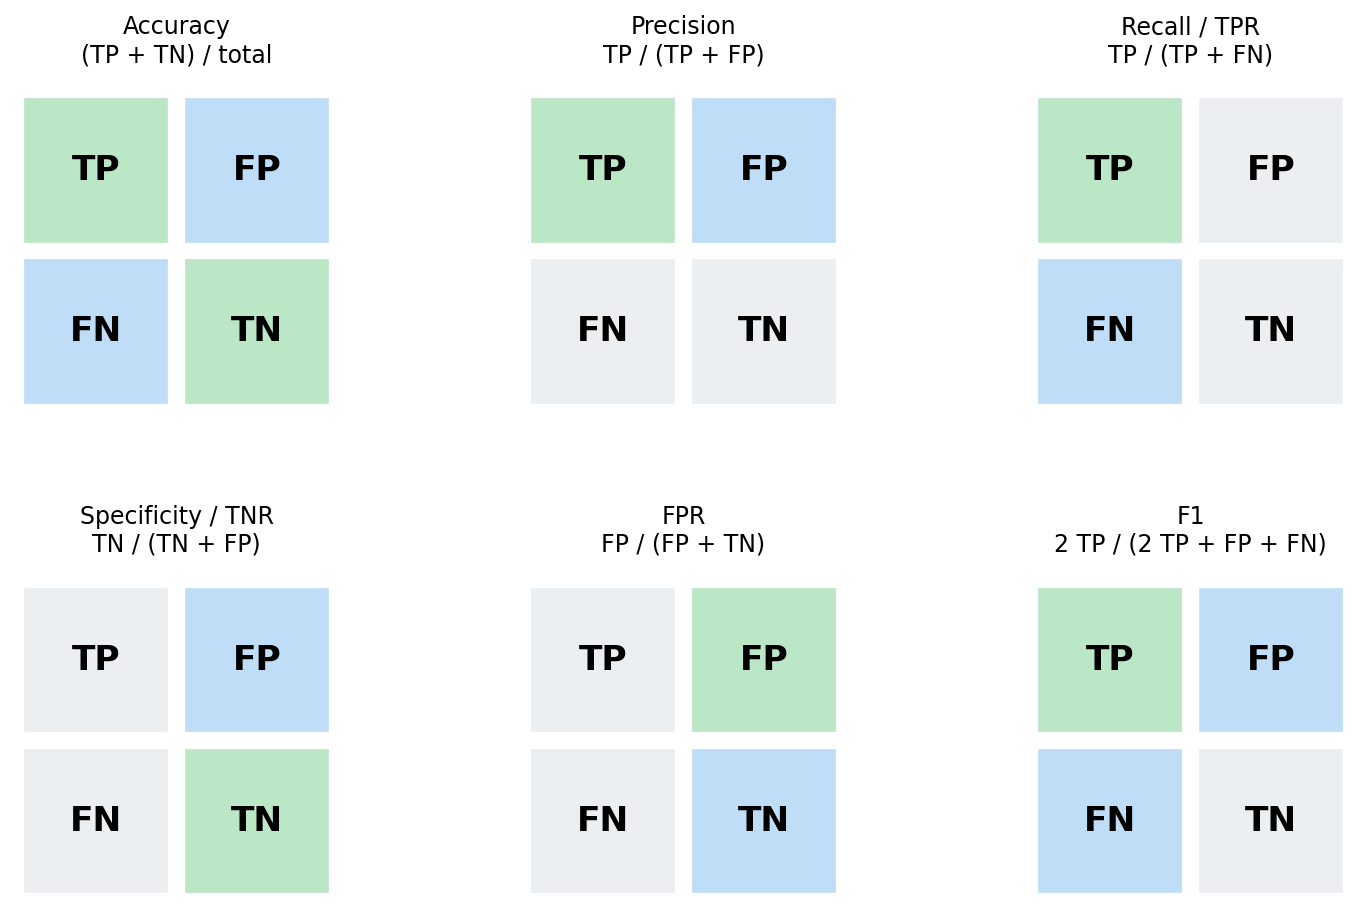

**Optional interactive exploration:** Run the following widget cell to select a metric and highlight its cells. If widgets are unavailable, the static image above contains the same information.

In [ ]:
# Optional: interactive confusion-matrix metric explorer.
# Install ipywidgets in the notebook environment if it is unavailable:
# conda install -c conda-forge ipywidgets
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    print("ipywidgets is not installed; use the static reference above.")
else:
    metric_specs = {
        "Accuracy": ("(TP + TN) / (TP + FP + FN + TN)", {"TP", "TN"}, {"TP", "FP", "FN", "TN"}),
        "Precision": ("TP / (TP + FP)", {"TP"}, {"TP", "FP"}),
        "Recall / TPR": ("TP / (TP + FN)", {"TP"}, {"TP", "FN"}),
        "Specificity / TNR": ("TN / (TN + FP)", {"TN"}, {"TN", "FP"}),
        "FPR": ("FP / (FP + TN)", {"FP"}, {"FP", "TN"}),
        "F1": ("2 TP / (2 TP + FP + FN)", {"TP"}, {"TP", "FP", "FN"}),
    }
    metric_dropdown = widgets.Dropdown(options=list(metric_specs), value="Precision", description="Metric:")
    metric_output = widgets.Output()

    def draw_metric(change=None):
        formula, numerator, denominator = metric_specs[metric_dropdown.value]
        with metric_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(4.7, 3.6))
            ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_aspect("equal"); ax.axis("off")
            for label, x, y in [("TP", 0, 1), ("FP", 1, 1), ("FN", 0, 0), ("TN", 1, 0)]:
                color = "#BCE7C6" if label in numerator else "#BFDDF7" if label in denominator else "#ECEFF1"
                ax.add_patch(plt.Rectangle((x + .03, y + .03), .94, .94, color=color))
                ax.text(x + .5, y + .5, label, ha="center", va="center", fontsize=18, weight="bold")
            ax.set_title(f"{metric_dropdown.value}\n{formula}", fontsize=11)
            plt.show()
            print("Green: numerator | Blue: denominator only | Gray: unused")

    metric_dropdown.observe(draw_metric, names="value")
    display(metric_dropdown, metric_output)
    draw_metric()

## 5. Logistic regression: probabilities versus labels

- `predict_proba(X)` returns one probability **per class**, ordered by `model.classes_`, **when the classifier implements this method**.
- `predict(X)` returns a class label. For ordinary binary logistic regression, its default decision boundary corresponds to a probability of **0.5** for the positive class.
- `decision_function(X)`, when available, returns **decision scores** (not necessarily probabilities). Some classifiers do not provide `predict_proba()`; for example, `SVC` has `decision_function()` by default, while probability estimates require `probability=True`. ROC and Precision–Recall curves can use decision scores as well as probabilities.
- Changing the **decision threshold** changes the labels, **not** the scores or the trained model.

`LogisticRegression` offers different solvers. Its default `lbfgs` does not require `random_state` to control a random training split; some other solvers use randomness. We omit it here.

### Five fictional sessions (illustration only)

| Session | `predict_proba(X)`: P(Purchase) | decision @ 0.30 | decision @ 0.50 | decision @ 0.70 |
|---|---:|---|---|---|
| A | 0.12 | No purchase | No purchase | No purchase |
| B | 0.34 | **Purchase** | No purchase | No purchase |
| C | 0.48 | **Purchase** | No purchase | No purchase |
| D | 0.67 | **Purchase** | **Purchase** | No purchase |
| E | 0.91 | **Purchase** | **Purchase** | **Purchase** |

Notice: the probabilities stay the same. Only the **decisions** change. We cannot calculate precision or recall without knowing the **actual labels**.

The probability column is the **purchase-class column** of `predict_proba(X)` (a teaching label, not Python syntax). `predict(X)` uses the default decision rule; custom thresholds require comparing these probabilities manually.

In [ ]:
# Reproduce the fictional example with a small array.
fake_purchase_probabilities = np.array([0.12, 0.34, 0.48, 0.67, 0.91])
example = pd.DataFrame({"predict_proba: P(Purchase)": fake_purchase_probabilities})
for threshold in [0.30, 0.50, 0.70]:
    example[f"decision @ {threshold:.2f}"] = fake_purchase_probabilities >= threshold
example

## 6. Evaluate the baseline **within training data**

We reserve `X_test` for one final evaluation. For learning and comparing approaches, use **out-of-fold (OOF)** predictions from `StratifiedKFold` on `X_train`.

Each observation's OOF score comes from a model trained **without that observation**. These scores can illustrate ROC, PR and thresholds without peeking at the final test set. The folds are not independent experiments, so avoid treating fold scores as independent measurements for a naive confidence interval.

In [ ]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
baseline = SkPipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1500)),
])

# OOF probabilities: each session is scored by a model that did not train on it.
oof_proba_matrix = cross_val_predict(
    baseline, X_train, y_train, cv=cv, method="predict_proba"
)
# The target labels are booleans and the classes are ordered [False, True].
# We select the True column explicitly using the class order.
positive_column = list(np.unique(y_train)).index(POSITIVE_CLASS)
oof_purchase_prob = oof_proba_matrix[:, positive_column]
oof_pred = oof_purchase_prob >= 0.50

print("OOF classification report (threshold = 0.50):")
print(classification_report(y_train, oof_pred, zero_division=0))
print("OOF AP:", round(average_precision_score(y_train, oof_purchase_prob), 3))
print("OOF ROC-AUC:", round(roc_auc_score(y_train, oof_purchase_prob), 3))

## 7. ROC versus Precision–Recall: different questions

**ROC curve:** For every possible threshold, how does **TPR (recall)** change relative to **FPR**? Its horizontal axis measures the fraction of *actual negatives* incorrectly flagged.

**PR curve:** For every possible threshold, how does **precision** (reliability of positive alerts) change as we increase **recall** (coverage of actual positives)? Precision is sensitive to positive prevalence.

**ROC-AUC** summarizes ranking discrimination across thresholds. **AP** summarizes the PR curve across thresholds. Neither chooses a business-optimal threshold automatically.

**Check for understanding (2 min):** If purchases are rare, which curve directly shows whether an alert saying *purchase* is likely to be correct? Which metric on that curve answers the question?

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_train, oof_purchase_prob, ax=axes[0], name="Logistic (OOF)")
PrecisionRecallDisplay.from_predictions(y_train, oof_purchase_prob, ax=axes[1], name="Logistic (OOF)")
axes[0].set_title("ROC: TPR versus FPR")
axes[1].set_title("PR: precision versus recall")
plt.tight_layout()
plt.show()

## 8. Changing thresholds without retraining

Lower thresholds generally increase recall, but often reduce precision. Higher thresholds generally do the reverse. These are tendencies, not guarantees for every finite dataset.

We use the **same OOF probabilities** to compare three thresholds. **ROC-AUC and AP remain unchanged** because the underlying scores/ranking do not change; precision, recall and F1 at the chosen threshold may change.

In [ ]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    labels = oof_purchase_prob >= threshold
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_train, labels, pos_label=True, zero_division=0),
        "recall": recall_score(y_train, labels, pos_label=True),
        "F1": f1_score(y_train, labels, pos_label=True, zero_division=0),
        "predicted_purchases": int(labels.sum()),
    })
pd.DataFrame(threshold_rows).round(3)

**Check for understanding (2 min):** Why do AP and ROC-AUC remain constant in the table above, even though precision and recall at the chosen threshold change? (Hint: what information do these summary metrics use?)

## 9. What should we try before reaching for SMOTE?

| Approach | What changes? | Potential benefit | Main limitation |
|---|---|---|---|
| **Choose the right metric** | Evaluation objective | Measures what matters | Does not change the model |
| **Change threshold** | Final decision rule | Adjusts precision/recall | Needs validation; not a new ranking |
| **Class weights** | Training loss | No duplicate or synthetic samples | May trade precision for recall; model-dependent |
| **Random oversampling** | Duplicates minority training rows | Keeps all majority examples | No new information; can overfit |
| **Random undersampling** | Removes majority training rows | Simpler/faster training | Discards potentially useful data |
| **SMOTE** | Synthesizes minority feature vectors | May help some boundaries | Unrealistic examples; sensitive to neighbor choice and geometry |

### Understanding `sampling_strategy` in binary classification

**The ratio always compares minority to majority counts after resampling, but the sampler changes a different count.** For random oversampling (and SMOTE):

$$\alpha_{os}=\frac{N_{minority,\ after}}{N_{majority,\ before}}$$

For random undersampling:

$$\alpha_{us}=\frac{N_{minority,\ before}}{N_{majority,\ after}}$$

With 100 majority and 20 minority examples, `sampling_strategy=0.5` gives:

The **minority-to-majority ratio** and **minority prevalence** are different quantities:

$$\alpha=\frac{N_{minority}}{N_{majority}}$$

$$p_{min}=\frac{N_{minority}}{N_{minority}+N_{majority}}$$

Dividing the numerator and denominator of prevalence by $N_{majority}$ gives:

$$\boxed{p_{min}=\frac{\alpha}{1+\alpha}}$$

Here $\alpha$ denotes the **ratio after resampling** (or the observed ratio for the original data). In oversampling, the minority count changes; in undersampling, the majority count changes. The ratio always compares minority to majority.

| Strategy | Majority after | Minority after | Minority / majority ratio ($\alpha$) | Minority prevalence ($p_{min}$) |
|---|---:|---:|---:|---:|
| Original | 100 | 20 | 0.20 (20%) | 16.7% |
| Random oversampling (0.5) | 100 | 50 | 0.50 (50%) | 33.3% |
| Random undersampling (0.5) | 40 | 20 | 0.50 (50%) | 33.3% |
| Balanced 1:1 (illustration) | 100 | 100 | 1.00 (100%) | 50.0% |

**Important:** `sampling_strategy=0.5` means **minority / majority = 0.5**, not 50% of the total. A 50/50 class distribution corresponds to ratio `1.0`. There is no requirement to balance training to 50/50.

**Multiclass note:** A float `sampling_strategy` is not supported for these samplers in multiclass problems. Use a dictionary of desired **final class counts** instead:

```python
# Illustrative example (not executed): assume B and C initially have <= 200 rows.
multiclass_sampler = RandomOverSampler(
    sampling_strategy={"class_B": 200, "class_C": 200},
    random_state=42,
)
# X_new, y_new = multiclass_sampler.fit_resample(X_train_multiclass, y_train_multiclass)
```

For `RandomUnderSampler`, dictionary targets must not exceed the existing class counts.

**SMOTE caveat:** It interpolates between minority neighbors, using `k_neighbors`. Its synthetic rows are not guaranteed to be realistic. With one-hot dummy columns, interpolating two valid category vectors can produce invalid fractional categories (e.g. `[0.4, 0.6]`). Euclidean distance on one-hot features also imposes a geometry that may be inappropriate for mixed data. Gower distance is one option for mixed-type similarity, but choosing a distance alone does not make synthetic rows valid.

**[`SMOTENC` — official documentation](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html) (optional concept):** handles mixed numeric/categorical features **together**, identifying which columns are categorical; it is **not** a sampler applied only to categorical columns. One possible order is `SMOTENC` on original mixed-type training data, followed by `ColumnTransformer` and the classifier. Feature scaling and distance assumptions still require care. We will not add this extra technique to the core experiment.

## 10. First, inspect samplers explicitly (training data only)

This short demonstration shows the mechanics. We preprocess and resample **only training data**, never the test set. For cross-validation, however, doing this **once before splitting into folds is incorrect**: preprocessing and sampling must be fitted separately within each training fold. That is what the next section fixes.

In [ ]:
X_train_transformed = preprocessor.fit_transform(X_train)
print("Original training counts:", y_train.value_counts().sort_index().to_dict())

samplers = {
    "Random over": RandomOverSampler(sampling_strategy=0.50, random_state=RANDOM_STATE),
    "Random under": RandomUnderSampler(sampling_strategy=0.50, random_state=RANDOM_STATE),
}
for name, sampler in samplers.items():
    _, y_resampled = sampler.fit_resample(X_train_transformed, y_train)
    print(f"{name} counts:", pd.Series(y_resampled).value_counts().sort_index().to_dict())

## 11. Stratified CV + resampling **inside each training fold**

`StratifiedKFold(n_splits=4)` creates **four folds** with approximately the original positive/negative proportions. During each iteration, three folds form the training portion and one is held out for validation.

`imblearn.pipeline.Pipeline` ensures that the sampler acts on the **training portion only**. The validation fold is transformed (using preprocessing learned on the training portion), but **never resampled**. The final test set is never used during CV.

The diagram below shows an illustrative **80% no-purchase / 20% purchase** distribution. The real dataset has its own proportions. The sampler's illustrative 50/50 result is **not a requirement**.

**Sequence in each iteration:** combine the three training folds → fit preprocessing and sampler on those training rows → train the classifier → transform and evaluate the untouched validation fold. Stratification preserves proportions; it does **not** balance the folds by itself.

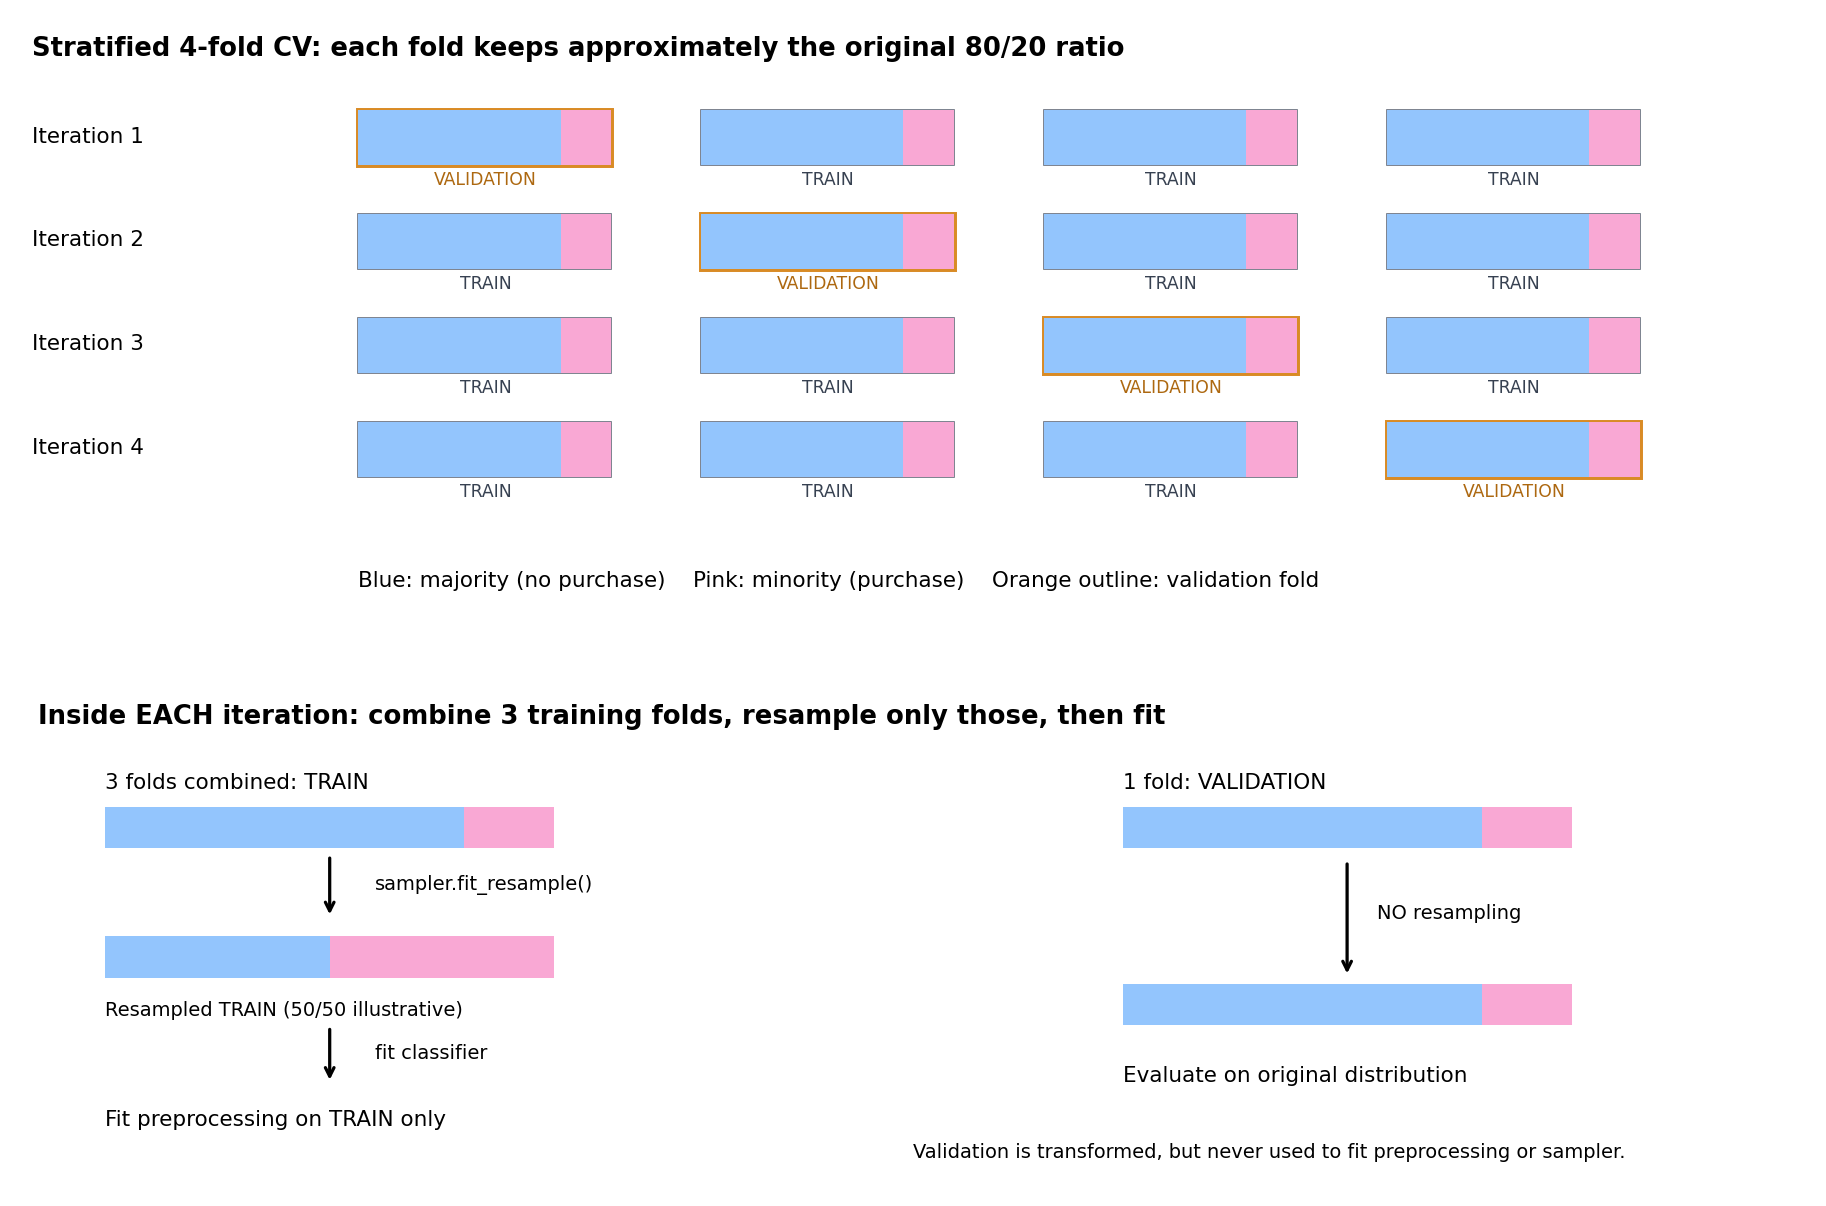

**Why not resample once before CV? Two problems:**
1. Validation folds may become artificially balanced, unlike real incoming data.
2. **Leakage:** synthetic points can depend on observations that later enter validation; random oversampling may place duplicates across training and validation.

A standard `sklearn.pipeline.Pipeline` cannot directly contain samplers using `fit_resample`. Use **`imblearn.pipeline.Pipeline`** for preprocessing, sampling and fitting inside each fold.

In [ ]:
def make_logistic_pipeline(sampler=None, class_weight=None):
    steps = [("prep", preprocessor)]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", LogisticRegression(
        max_iter=1500, class_weight=class_weight
    )))
    return ImbPipeline(steps)

strategies = {
    "No resampling": make_logistic_pipeline(),
    "Class weights": make_logistic_pipeline(class_weight="balanced"),
    "Random over": make_logistic_pipeline(
        RandomOverSampler(sampling_strategy=0.50, random_state=RANDOM_STATE)
    ),
    "Random under": make_logistic_pipeline(
        RandomUnderSampler(sampling_strategy=0.50, random_state=RANDOM_STATE)
    ),
}

rows = []
for name, estimator in strategies.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"ap": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=-1,
    )
    # cross_validate returns arrays of fold scores in a dictionary.
    # It does NOT average the scores or choose a winning metric for us.
    rows.append({
        "strategy": name,
        "mean_AP": scores["test_ap"].mean(),
        "std_AP": scores["test_ap"].std(),
        "mean_ROC_AUC": scores["test_roc_auc"].mean(),
    })
results = pd.DataFrame(rows).sort_values("mean_AP", ascending=False)
results.round(3)

**Reading `cross_validate`:** With multiple `scoring` entries, it returns a dictionary with arrays such as `scores["test_ap"]`, `scores["test_roc_auc"]`, `scores["fit_time"]` and `scores["score_time"]`. Each test-score array has **one value per fold**. The `.mean()` calls above are **our own calculations**. If you pass a *single* scoring string, the fold scores appear under `"test_score"`.

**Check for understanding (2 min):** Why do we choose the metric *before* deciding which strategy is best? What does a higher AP tell us, and what does it **not** tell us about a specific threshold?

## 12. SMOTE: an experiment, **not** an automatic recommendation

`SMOTE(k_neighbors=5)` uses nearby minority observations to interpolate synthetic feature vectors. Its neighbor count is another hyperparameter and its output depends on the chosen feature representation.

**Important limitation in this dataset:** The next experiment applies ordinary SMOTE **after one-hot encoding** only to demonstrate the CV-safe pipeline. Fractional dummy values may not represent real shopping sessions. The comparison is therefore **illustrative**, not a recommendation to deploy SMOTE on these features. For mixed data, investigate `SMOTENC` separately.

In [ ]:
smote_pipeline = make_logistic_pipeline(
    SMOTE(sampling_strategy=0.50, k_neighbors=5, random_state=RANDOM_STATE)
)
smote_scores = cross_validate(
    smote_pipeline, X_train, y_train, cv=cv,
    scoring={"ap": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1,
)
smote_row = pd.DataFrame([{
    "strategy": "SMOTE (illustrative only)",
    "mean_AP": smote_scores["test_ap"].mean(),
    "std_AP": smote_scores["test_ap"].std(),
    "mean_ROC_AUC": smote_scores["test_roc_auc"].mean(),
}])
pd.concat([results, smote_row], ignore_index=True).sort_values(
    "mean_AP", ascending=False
).round(3)

**Check for understanding (3 min):** Suppose we apply SMOTE to all of `X_train` *before* `cross_validate`. Explain **both** (a) why validation-fold class proportions may be unrealistic and (b) how information from future validation observations may influence synthetic training rows.

## 13. Does imbalance affect every classifier equally?

No. Compare logistic regression with scikit-learn's [**`HistGradientBoostingClassifier`**](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html). This is an exploratory comparison, **not** a reproduction of research on XGBoost and LightGBM and not evidence that any algorithm is universally strong or weak.

We use the same CV partitions and compare **AP without sampling** versus **AP with random oversampling**. A gain is not guaranteed.

In [ ]:
tree_strategies = {
    "HistGB baseline": ImbPipeline([
        ("prep", preprocessor),
        ("model", HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE)),
    ]),
    "HistGB + random over": ImbPipeline([
        ("prep", preprocessor),
        ("sampler", RandomOverSampler(sampling_strategy=0.50, random_state=RANDOM_STATE)),
        ("model", HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE)),
    ]),
}

comparison_rows = []
for name, estimator in {
    "Logistic baseline": strategies["No resampling"],
    "Logistic + random over": strategies["Random over"],
    **tree_strategies,
}.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring="average_precision", n_jobs=-1,
    )
    comparison_rows.append({"strategy": name, "mean_AP": scores["test_score"].mean()})
pd.DataFrame(comparison_rows).round(3)

**Interpretation:** Does oversampling improve AP for both algorithms? By the same amount? Differences in mean fold scores are **descriptive**, not a formal significance test. The model, features, objective and tuning all matter.

## 14. Final evaluation — once on untouched test data

For this demonstration, select the highest training-CV-AP approach among the **four non-SMOTE logistic-regression strategies**. We intentionally exclude the illustrative SMOTE experiment from automatic selection because of the mixed-feature interpolation concern.

Fit on the **full training set**, then evaluate on the untouched test set **once**. We use threshold 0.5 for the classification report; choosing a business-optimal threshold requires a separate validation procedure.

In [ ]:
selected_name = results.iloc[0]["strategy"]
selected_model = strategies[selected_name]
selected_model.fit(X_train, y_train)

final_pred = selected_model.predict(X_test)
final_probabilities = selected_model.predict_proba(X_test)
positive_column = list(selected_model.classes_).index(POSITIVE_CLASS)
final_purchase_prob = final_probabilities[:, positive_column]

print("Selected using training CV AP:", selected_name)
print(classification_report(y_test, final_pred, zero_division=0))
print("Test AP:", round(average_precision_score(y_test, final_purchase_prob), 3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, final_purchase_prob), 3))

# Plot with our convention: predicted rows, actual columns.
cm = confusion_matrix(y_test, final_pred, labels=[False, True]).T
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["No purchase", "Purchase"],
       yticklabels=["No purchase", "Purchase"],
       xlabel="Actual", ylabel="Predicted", title="Final test confusion matrix")
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## 15. Final guided challenge (10–15 minutes)

**Business question:** You want to identify purchase sessions while limiting unreliable purchase alerts. Compare a baseline logistic regression against a class-weighted model, using **the training data only** and the same stratified folds.

The pipeline and CV object already exist. Complete the **four meaningful decisions** below (the code scaffolding is provided). Do **not** use `X_test` in this exercise.

1. Configure the weighted model appropriately.
2. Choose the scorer that summarizes the PR curve across thresholds.
3. Extract the corresponding fold scores and calculate their mean.
4. Explain whether the weighted model improves the chosen metric, and why this alone does not prove it is the best choice at threshold 0.5.

*Hint:* See the table in Section 9 and the dictionary keys discussed after `cross_validate`.

In [ ]:
# Guided exercise — fill the four TODOs, then interpret your result.
exercise_models = {
    "baseline": make_logistic_pipeline(),
    "weighted": make_logistic_pipeline(class_weight=...),  # TODO 1
}

exercise_rows = []
for name, estimator in exercise_models.items():
    fold_results = cross_validate(
        estimator, X_train, y_train, cv=cv,
        scoring={"ap": ...},  # TODO 2: select the PR-curve summary metric
        n_jobs=-1,
    )
    ap_scores = fold_results[...]  # TODO 3: correct dictionary key
    exercise_rows.append({
        "model": name,
        "mean_AP": ...,  # TODO 4: mean of fold AP scores
    })

# When TODOs are completed:
# exercise_summary = pd.DataFrame(exercise_rows)
# display(exercise_summary)
# Discussion: Does higher AP guarantee better precision at threshold 0.5? Why not?

## 16. Final takeaways

1. **Define the positive class based on the decision**, not class frequency.
2. **Accuracy can be misleading**; precision, recall, F1, ROC-AUC and AP answer different questions.
3. **AP summarizes the PR curve** and differs from trapezoidal PR-AUC.
4. **Try metrics, thresholds and class weights before assuming SMOTE is necessary.**
5. **Stratify folds and resample only within training folds** using `imblearn.pipeline.Pipeline`.
6. **50/50 is not a universal target**. SMOTE's synthetic rows and `k_neighbors` require scrutiny.
7. **Models respond differently**; compare empirically instead of assuming that resampling helps.

> **The goal is not to balance the dataset. The goal is to improve decisions for the real problem.**

**Exit ticket:** What is a false negative in a poisonous-mushroom classifier? Why can precision be undefined? Why is SMOTE-before-CV unsafe? What changes when the threshold moves?

**Next:** Apply these ideas to the credit-card fraud lab. Optional self-learning will cover Youden's J, costs, probability calibration and stronger boosting libraries.